In [2]:
import numpy as np

# CONST
mu_0 = 4 * np.pi * 1e-7
rho_copper = 1 / 5.96e7
k_b = 1.38e-23
temp = 300

## 透地磁耦合通信的分析

### 系统设置
对于发送端，假定其采用了内径为$a_{tx}$的铜制电缆，绕成了匝数为$n_{tx}$，半径为$r_{tx}$的圆形线圈。发送端中的峰值电流为$I_{tx}$，电流频率为$f$，而至于如何产生该电流则留待后续的电气设计部分进一步考虑。

对于接收端，假定采用了内径为$a_{rx}$的铜质电缆，绕成了匝数为$n_{rx}$，半径为$r_{rx}$的圆形线圈，并且圆形线圈中放置了一个磁导率为$\mu_{rx}$的铁氧体磁芯，磁芯的半径为$r_{rx,magnet}$，长度为$l_{rx,magnet}$

收发端先假定线圈是同轴对齐的。二者之间的距离为$d$。

In [ ]:
a_tx = 2e-3
n_tx = 25
r_tx = 0.75
i_tx = 30

a_rx = 0.02e-3
n_rx = 10000
r_rx = 0.016 # 6 cm直径
r_rx_magnet = 0.016
l_rx_magnet = 0.23
mu_rx = 800

theta = 0 # degrees
d = 200
f = 10000
B = 20 # 10 bps

### 发射磁感应强度
令发射机磁矩$m_{tx}=r_{tx}^2\pi I_{tx} n_{tx}$，则在较远的距离$d$下，磁感应强度表示为：

$
B_r=\frac{\mu_0}{2\pi}\frac{m_{tx}\cos{(\theta)}}{d^3} \\
B_{\theta}=\frac{\mu_0}{4\pi}\frac{m_{tx}\sin{(\theta)}}{d^3}
$

如果收发双端的轴线对齐，那么通过接收端的磁感应强度为：

$B_{rx}=\frac{\mu_0}{2\pi}\frac{m_{tx}}{d^3}$

更加精确的解是：

$B_{rx}=\frac{\mu_0 m_{tx}}{2\pi (r_{tx}^2 + d^2)^{3/2}}$

In [28]:
m_tx = (r_tx ** 2) * np.pi * i_tx * n_tx
b_r = mu_0 / (2 * np.pi) * (m_tx * np.cos(np.radians(theta))) / (d ** 3)
b_theta = mu_0 / (4 * np.pi) * (m_tx * np.sin(np.radians(theta))) / (d ** 3)

# if co-axial
b_rx_approx = mu_0 / (2 * np.pi) * (m_tx) / (d ** 3)
b_rx_precise = (mu_0 * m_tx) / (2 * np.pi * (r_tx ** 2 + d ** 2) ** (3 / 2))
b_rx = b_rx_approx

print(f"目标处的磁场强度: {b_rx} T")

目标处的磁场强度: 0.0002650718801466388 T


### 接收线圈的感应电动势
对于一个开路磁芯，它的对外有效磁导率表示为：

$\mu_{eff,rx}=\frac{\mu_{rx}}{1+N_d(\mu_{rx}-1)}$

其中$N_d=\frac{1}{\gamma^2-1}(\frac{\gamma}{\sqrt{\gamma^2-1}}\ln{(\gamma+\sqrt{\gamma^2-1}})-1)$，$\gamma$为线圈的长径比。

如果使用的磁棒是细长的，即$\gamma \gg 1$，则$N_d \approx \frac{\ln{(2\gamma)}-1}{\gamma^2}$。
而一般的铁氧体磁芯的磁导率$\mu_{rx}$通常在$10^2$到$10^4$之间，因此可以近似认为$\mu_{eff,rx} \approx \frac{1}{N_d}= \frac{\gamma^2}{\ln{(2\gamma)}-1}$。

单匝线圈通过的磁通量为：
$\Phi_{rx}=\mu_{eff,rx} B A_{rx,magnet} + B(A_{rx} - A_{rx,magnet})$，
其中$A_{rx}=\pi r_{rx}^2$，即接收线圈的面积，而$A_{rx,magnet}=\pi r_{rx,magnet}^2$，即磁棒的截面积。在铁氧体的作用下，有效接收面积变为了：
$A_{eff,rx}=\mu_{eff,rx} A_{rx,magnet} + (A_{rx} - A_{rx,magnet})$。

在开路环境下，接收线圈的感应电动势为：

$E_{rx}=-n_{rx}\frac{d\Phi_{rx}}{dt}=-n_{rx}A_{eff,rx}\frac{dB}{dt}$

假定发射端的电流为正弦波，频率为$f$，则接收线圈处的磁感应强度为：

$B_{rx}(t)=B_{rx}\sin{(2\pi ft)}$

因此接收线圈的感应电动势为：

$E_{rx}(t)=-n_{rx}A_{rx,magnet} 2\pi f B_{rx} \cos{(2\pi ft)}$

In [5]:
gamma = l_rx_magnet / r_rx_magnet / 2 # 长径比
nd = 1 / (gamma ** 2 - 1) * (gamma / np.sqrt(gamma ** 2 - 1) * np.log(gamma + np.sqrt(gamma ** 2 - 1)) - 1)
mu_eff_rx = mu_rx / (1 + (mu_rx - 1) * nd)
print(f"等效磁导率: {mu_eff_rx} H/m")
area_rx_magnet = r_rx_magnet ** 2 * np.pi
area_rx = r_rx ** 2 * np.pi
a_eff_rx = mu_eff_rx * area_rx_magnet + (area_rx - area_rx_magnet)
e_rx = np.abs(n_rx * a_eff_rx * 2 * np.pi * f * b_rx)
print(f"感应电动势: {e_rx} V")

等效磁导率: 28.982385518791688 H/m
感应电动势: 0.00024263168334770783 V


上述的计算可以使用接收线圈的灵敏度计算。灵敏度表示为感应电压相对于磁场变化率的微分。接收线圈的灵敏度$\sigma_{rx}$可以表示为：

$\sigma_{rx} = N_{rx}A_{eff,rx}$

根据灵敏度，可以在任何一个磁场环境下计算出接收线圈的感应电动势，即：

$E_{rx} = \sigma_{rx} 2\pi f B_{rx}$

In [6]:
sigma_rx = n_rx * a_eff_rx
e_rx_sigma = sigma_rx * 2 * np.pi * f * b_rx
print(f"线圈灵敏度：{sigma_rx} V/(T/s)")
print(f"基于灵敏度计算的感应电动势: {e_rx_sigma} V")

线圈灵敏度：116.54508726955925 V/(T/s)
基于灵敏度计算的感应电动势: 0.00024263168334770783 V


### 接收信噪比分析
对于接收线圈的信噪比，我们只考虑接收线圈的热噪声。忽略低频信号的趋肤效应，上述接收线圈的电阻为：

$R_{rx} = \rho_{copper} \frac{2 N_{rx} \pi r_{rx}}{\pi a_{rx}^2}$

那么接收线圈的热噪声均方根电压为：

$V_{noise,thermal} = \sqrt{4 k_B T R_{rx} B}$

其中$k_B$为玻尔兹曼常数（1.38e-23 J/K），$T$为绝对温度（300 K），$B$为接收机的带宽（设定为 20 Hz，对应 10 bps）。

因此可以计算得到接收线圈的信噪比为：

$SNR_{rx} = \frac{E_{rx}}{V_{noise,rx}}$

In [7]:
res_rx = rho_copper * (2 * np.pi * r_rx * n_rx) / (np.pi * a_rx ** 2)
print(f"接收线圈的线长度: {2 * np.pi * r_rx * n_rx} m")
print(f"接收线圈的电阻: {res_rx} Ω")
v_noise_thermal = np.sqrt(4 * k_b * temp * res_rx * B)
snr_rx = e_rx / v_noise_thermal
print(f"接收线圈的热噪声电压: {v_noise_thermal} V")
print(f"接收线圈的信噪比: {20 * np.log10(snr_rx)} dB")

接收线圈的线长度: 502.65482457436696 m
接收线圈的电阻: 6711.409395973155 Ω
接收线圈的热噪声电压: 4.7146779231950825e-08 V
接收线圈的信噪比: 74.22990962912397 dB


由此可见，由于频率较低以及线圈电阻很小，噪声电压并不会显著影响接收线圈的信噪比，但是我们需要进一步考虑后续的放大电路对信噪比的影响。以OPA486为例，其输入噪声电压密度为$V_{ndense,amp}$（9.2e-9 V/sqrtHz），输入的电流噪声密度为$I_{ndense,amp}$（2e-10 A/sqrtHz）。假定放大器配置为同相放大状态，放大反馈电阻为$R_f$和$R_g$（19 kΩ和1 kΩ），增益为$A_v=1+\frac{R_f}{R_g}$，则放大器的噪声密度可以通过以下公式计算：

输入噪声电压密度：$V_{ndense,amp}$

噪声电流引起的输入噪声电压（正极输入端）：$I_{ndense,amp} R_{rx}$

噪声电流引起的输入噪声电压（负极输入端）：$I_{ndense,amp} (R_f || R_s)$

反馈电阻噪声：$\sqrt{\frac{4 k_B T R_f}{A_v ^ 2} + 4 k_B T R_s}$

最终的放大器输入噪声密度为：

$\sqrt{V_{ndense,amp}^2 + (I_{ndense,amp}R_{rx})^2 + (I_{ndense,amp}(R_f || R_s))^2 + \frac{4 k_B T R_f}{A_v ^ 2} + 4 k_B T R_s}$

In [8]:
v_ndense_amp = 9.2e-9
i_ndense_amp = 2e-10
r_f = 19e3
r_s = 1e3
a_v = r_f / r_s + 1
v_noise_amp = np.sqrt(v_ndense_amp**2 + (i_ndense_amp * res_rx)**2 + (i_ndense_amp/(1/r_f + 1/r_s))**2 + 4*k_b*temp*r_f/a_v**2 + 4*k_b*temp*r_s)
v_noise_amp = v_noise_amp * np.sqrt(B)
v_noise_rx = np.sqrt(v_noise_thermal ** 2 + v_noise_amp ** 2)
snr_rx = e_rx / v_noise_rx
print(f"接收线圈的总噪声电压: {v_noise_rx} V")
print(f"接收线圈的信噪比: {20 * np.log10(snr_rx)} dB")

throughput = B * np.log2(1 + snr_rx)
print(f"最大可达数据率: {throughput} bps")

接收线圈的总噪声电压: 6.0630582559527955e-06 V
接收线圈的信噪比: 32.04511540400895 dB
最大可达数据率: 107.1637301784451 bps


由此可见，主要影响接收线圈灵敏度的是第一级放大器的噪声。在经过第一级放大之后，后续的放大器的噪声对信噪比的影响可以忽略不计。

如果考虑在放大器之前加入一个电容谐振以增加线圈的输出电压（假定输出被放大了$A_{res}$倍），则接收线圈的信噪比可以表示为：

$SNR_{rx} = \frac{A_{res} E_{rx}}{\sqrt{(V_{noise,thermal} A_{res})^2 + (V_{noise,amp})^2}}$

In [9]:
a_v_res = 10
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)
print(f"接收线圈的谐振总噪声电压: {v_noise_rx} V")
print(f"接收线圈的谐振信噪比: {20 * np.log10(snr_rx_resonance)} dB")

接收线圈的谐振总噪声电压: 6.0630582559527955e-06 V
接收线圈的谐振信噪比: 52.01919490168383 dB


### 基本结论

根据上述的仿真计算，我们可以得到如下的结论：

1. 在线圈完全对齐，使用磁芯，发射线圈电流为数十A（一个较大的电流）的情况下，接收线圈上的感应电压一般为uV的量级；
2. 增加发射线圈的电流、匝数、尺寸，或者增加接收线圈的匝数、尺寸均可以提高接收线圈的感应电压。尤其是半径的增加可以以平方量级提高接收线圈的感应电压；但是上述参数的增加均受到实际工程的限制；
3. 接收线圈的信噪比主要受第一级放大器的噪声（尤其是 1/f 噪声和反馈电阻的热噪声）的影响，线圈热噪声不会显著影响接收线圈的信噪比，这和射频通信的情况不同；
4. 在我们设置的若干个理想参数的情况下，接收线圈上的信噪比大约为10~20 dB。

### 现实部署仿真

我们仿真在现实部署下的情况，主要考虑以下几种情况：

1. 线圈的方向并不完全对齐；
2. 计算线圈的耗散功率以及质量问题；
3. 线圈的电气参数；
4. 使用Orica的多级线圈组合方案；

#### 不对齐的线圈方向

假定实际部署中，发射线圈的平面是垂直于地面的（发射线圈平面的法向量平行于地面），而地下的雷管线圈平面平行于地面（线圈平面的法向量垂直于地面），并不满足此前两个线圈同轴的假设。因此需要在新的模型下进行计算。

重新更新设置，令收发双端在水平面上的距离为$d$，接收机位于地下$s$m处，并且保证$\sqrt{d^2+s^2} \gg r_{tx}$。

In [10]:
d = 200
s = 30

现在重新计算接收线圈处的磁感应强度。磁感应强度的远场强度为

$
B_r=\frac{\mu_0}{2\pi}\frac{m_{tx}\cos{(\theta)}}{r^3} \\
B_{\theta}=\frac{\mu_0}{4\pi}\frac{m_{tx}\sin{(\theta)}}{r^3} \\
B_{\phi}=0
$

这是球坐标下的表示方法，其中$r$是发射线圈到接收线圈的距离，$\theta$是**接收线圈和发射线圈中心的连线**与**发射线圈平面法向量**的夹角。因此上述的式子可以使用：

$
r = \sqrt{d^2+s^2} \\
\theta = \arctan{(\frac{s}{d})}
$

代入计算。而上述磁场穿过接收线圈平面的分量为：

$B_{rx} = B_r \sin{(\theta)} + B_{\theta} \cos{(\theta)}$

In [11]:
r = np.sqrt(d ** 2 + s ** 2)
theta = np.arctan(s / d)
m_tx = (r_tx ** 2) * np.pi * i_tx * n_tx
b_r = mu_0 / (2 * np.pi) * (m_tx * np.cos(theta)) / (r ** 3)
b_theta = mu_0 / (4 * np.pi) * (m_tx * np.sin(theta)) / (r ** 3)
b_rx = b_r * np.sin(theta) + b_theta * np.cos(theta)

print(f"目标处的磁场强度: {b_rx} T")

目标处的磁场强度: 7.051766087007598e-12 T


随后就可以使用接收线圈的灵敏度直接计算出接收线圈的感应电动势：

$E_{rx} = \sigma_{rx} 2\pi f B_{rx}$

并且可以和上述内容一样，进一步计算出接收线圈的信噪比（考虑使用电容谐振的情况），所有假设和参数均不变。

In [12]:
e_rx = sigma_rx * 2 * np.pi * f * b_rx
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)
print(f"接收线圈的感应电动势： {e_rx} V")
print(f"接收线圈的谐振信噪比： {20 * np.log10(snr_rx_resonance)} dB")
throughput = B * np.log2(1 + snr_rx_resonance)
print(f"最大可达数据率: {throughput} bps")

接收线圈的感应电动势： 5.163827638958641e-05 V
接收线圈的谐振信噪比： 38.57967942994211 dB
最大可达数据率: 128.49673354787112 bps


由此可见，在实际部署中，接收线圈的感应电动势和信噪比会因为线圈方向不对齐而显著下降。

我们进一步研究了接收线圈的感应电动势和信噪比随距离的变化情况。假定上述数据均不变，接收线圈的距离从50 m到400 m变化，则有如下的计算结果：

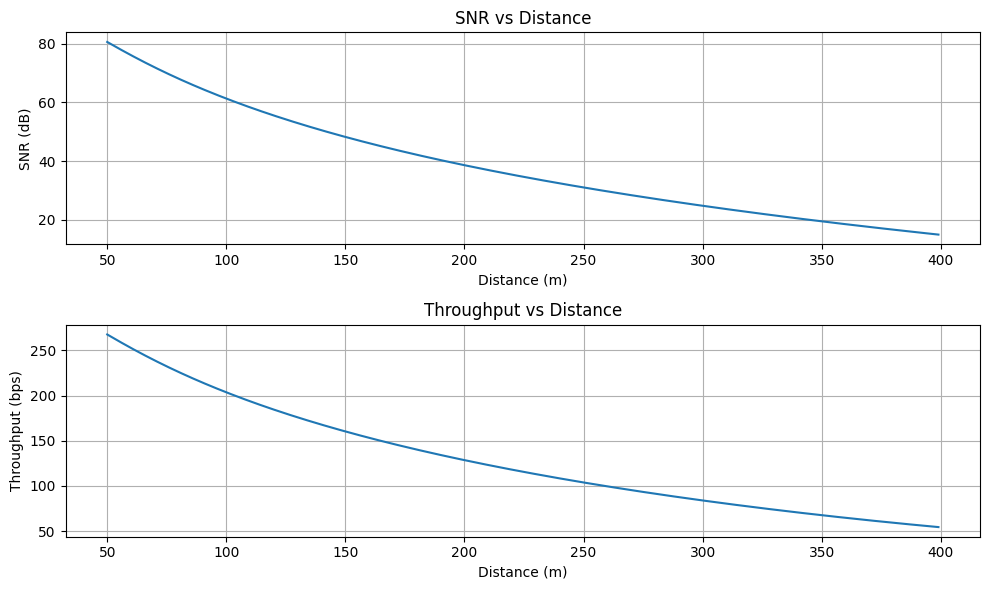

In [13]:
d_range = np.arange(50, 400, 1)
r = np.sqrt(d_range ** 2 + s ** 2)
theta = np.arctan(s / d_range)
b_r = mu_0 / (2 * np.pi) * (m_tx * np.cos(theta)) / (r ** 3)
b_theta = mu_0 / (4 * np.pi) * (m_tx * np.sin(theta)) / (r ** 3)
b_rx = b_r * np.sin(theta) + b_theta * np.cos(theta)

e_rx = sigma_rx * 2 * np.pi * f * b_rx
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)
throughput = B * np.log2(1 + snr_rx_resonance)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(d_range, 20 * np.log10(snr_rx_resonance))
plt.title("SNR vs Distance")
plt.xlabel("Distance (m)")
plt.ylabel("SNR (dB)")
plt.grid()
plt.subplot(2, 1, 2)
plt.plot(d_range, throughput)
plt.title("Throughput vs Distance")
plt.xlabel("Distance (m)")
plt.ylabel("Throughput (bps)")
plt.grid()
plt.tight_layout()

同时我们也研究在不同深度下的接收线圈的感应电动势和信噪比随距离的变化情况。假定接收线圈就在地下5到50 m的范围内，则有如下的计算结果：

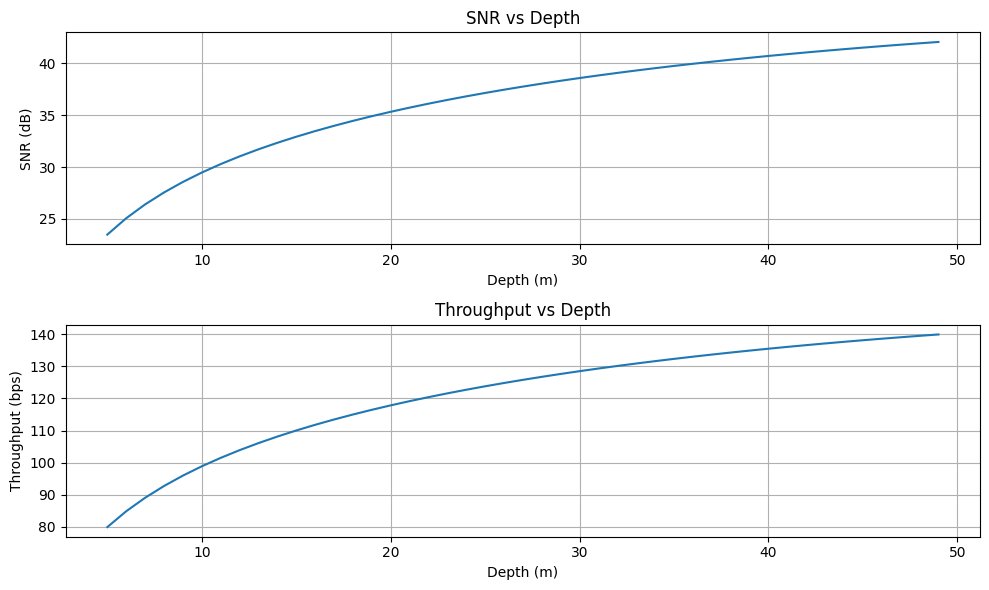

In [14]:
s_range = np.arange(5, 50, 1)
r = np.sqrt(d ** 2 + s_range ** 2)
theta = np.arctan(s_range / d)
b_r = mu_0 / (2 * np.pi) * (m_tx * np.cos(theta)) / (r ** 3)
b_theta = mu_0 / (4 * np.pi) * (m_tx * np.sin(theta)) / (r ** 3)
b_rx = b_r * np.sin(theta) + b_theta * np.cos(theta)
e_rx = sigma_rx * 2 * np.pi * f * b_rx
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)
throughput = B * np.log2(1 + snr_rx_resonance)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(s_range, 20 * np.log10(snr_rx_resonance))
plt.title("SNR vs Depth")
plt.xlabel("Depth (m)")
plt.ylabel("SNR (dB)")
plt.grid()
plt.subplot(2, 1, 2)
plt.plot(s_range, throughput)
plt.title("Throughput vs Depth")
plt.xlabel("Depth (m)")
plt.ylabel("Throughput (bps)")
plt.grid()
plt.tight_layout()


#### 发射线圈的耗散功率和质量问题

发射线圈本身会有发热的问题。具体而言，发热功率可以表示为：

$
P_{tx,dissipation} = I_{tx}^2 R_{tx} \\ 
R_{tx} = \rho_{copper} \frac{2 N_{tx} \pi r_{tx}}{\pi a_{tx}^2}
$

In [15]:
res_tx = rho_copper * (2 * np.pi * r_tx * n_tx) / (np.pi * a_tx ** 2)
p_tx_dissipation = i_tx ** 2 * res_tx
print(f"发射线圈的电阻: {res_tx} Ω")
print(f"发射线圈的耗散功率: {p_tx_dissipation} W")

发射线圈的电阻: 0.15729865771812082 Ω
发射线圈的耗散功率: 141.56879194630875 W


实际上，这个电阻非常的小，通常在几百毫欧的量级。然而它的发热功率仍然是不可忽视的。上述电功率可以明显地导致发射线圈温度的升高，该发射机不能长时间地工作。

然而，相比较于发射线圈的耗散功率，发射驱动电路的设计则是更加困难的问题。该发射驱动电路需要驱动数十毫欧的线圈负载，并且需要在数十安培的电流下工作。这要求驱动电路有很大的拉电流以及低内阻。

后续将会进一步分析发射电路的电气要求。

随后我们考虑接收机的重量问题。接收机仅考虑线圈和磁棒的质量。铜线的体积为：$\pi a_{rx}^2 \times 2 \pi n_{rx} r_{rx} $，而磁棒的体积为：$\pi r_{rx}^2 \times 2 r_{rx} \gamma$，其中$\gamma$为磁棒的长径比。假定铜线的密度为$\rho_{density,copper}$，磁棒的密度为$\rho_{density,magnet}$，则接收机的总质量为：

$M_{rx} = \rho_{density,copper} \pi a_{rx}^2 \times 2 \pi n_{rx} r_{rx} + \rho_{density,magnet} \pi r_{rx}^2 \times 2 r_{rx} \gamma$

In [16]:
v_copper_line = np.pi * a_rx**2 * 2 * np.pi * n_rx * r_rx
v_magnet = np.pi * r_rx_magnet**2 * 2 * r_rx * gamma
rho_density_copper = 8.96e3
rho_density_magnet = 5e3
mass_rx = rho_density_copper * v_copper_line + rho_density_magnet * v_magnet
print(f"接收机的总质量: {mass_rx} kg")
print(f"接收机的铜线质量: {rho_density_copper * v_copper_line} kg")
print(f"接收机的磁棒质量: {rho_density_magnet * v_magnet} kg")

接收机的总质量: 0.9305445031645958 kg
接收机的铜线质量: 0.005659625947760683 kg
接收机的磁棒质量: 0.9248848772168351 kg


这个重量已经超过了实际部署的要求，主要的重量其实来自于铁质的磁芯。我们暂时不考虑这个问题。

#### 线圈的电气参数

这一段我们验证上述线圈的电气参数以及电路的可实现性。

首先我们讨论发射线圈的电气参数。发射线圈的电感根据Wheeler公式（SI单位）可以表示为：

$L_{tx} = 3.937 \times 10^{-5} \frac{n_{tx}^2r_{tx}^2}{9r_{tx} + 10a_{tx}}$

直接驱动这个线圈需要驱动电路输出极大的电流。因此我们一般需要使用一个电容谐振电路来降低驱动电路的输出电流。假定我们使用一个电容$C_{tx}$与发射线圈串联，则输入的阻抗为：

$Z_{in,tx} = \frac{1}{j\omega C_{tx}} + R_{tx} + j\omega L_{tx}$

线圈的Q值为$Q_{tx} = \frac{\omega L_{tx}}{R_{tx}}$。一般而言我们让电容和线圈在工作频率$f$下谐振，则有：

$C_{tx} = \frac{1}{\omega^2 L_{tx}}$

此时系统的输入阻抗为：

$Z_{in,tx} = R_{tx}$

驱动器需要给入的输入电压和输入电流分别为：

$V_{in,tx} = I_{tx} R_{tx} \\
I_{in,tx} = I_{tx}$

也就是说驱动器需要给出完整的电流$I_{tx}$，而不需要额外的电压。由于发射线圈的电阻非常小，因此驱动器本身所需要的输出电压并不会很大。但是在谐振状态下，电容和线圈两端的电压会非常大，具体来说电压峰值为：

$V_{tx,coil} = I_{tx} \omega L_{tx} \\
V_{tx,cap} = \frac{I_{tx}}{\omega C_{tx}}$

In [17]:
l_tx = 3.937e-5 * n_tx**2 * r_tx**2 / (9 * r_tx + 10 * a_tx)
print(f"发射线圈的电感: {l_tx} H")
omega = 2 * np.pi * f
q_tx = omega * l_tx / res_tx
print(f"发射线圈的品质因数: {q_tx}")
c_tx = 1 / (omega ** 2 * l_tx)
print(f"发射线圈的谐振电容: {c_tx} F")
v_in_tx = i_tx * res_tx
print(f"发射驱动电路的输入电压: {v_in_tx} V")
i_in_tx = v_in_tx / res_tx
print(f"发射驱动电路的输入电流: {i_in_tx} A")
v_tx_coil = i_tx * omega * l_tx
v_tx_cap = i_tx / (omega * c_tx)
print(f"发射线圈的电压: {v_tx_coil} V")
print(f"发射电容的电压: {v_tx_cap} V")

发射线圈的电感: 0.0020444631646971937 H
发射线圈的品质因数: 816.6465692615669
发射线圈的谐振电容: 1.2389705203779558e-07 F
发射驱动电路的输入电压: 4.718959731543625 V
发射驱动电路的输入电流: 30.0 A
发射线圈的电压: 3853.722275248586 V
发射电容的电压: 3853.722275248586 V


系统的谐振状态在实际情况下并不是完全精确的，因此实际的驱动电压需要能够产生比上述电压更大的电压，以保证系统的正常工作。

#### Orica的多级线圈组合方案

Orica的多级线圈组合方案本质上是一个多匝的线圈的组合。这样可以减少每一个线圈的匝数，进而降低每一个线圈的电阻，降低单个线圈的发热功率以及对应的驱动电路的性能要求。在系统建模上，如果多个线圈的距离远小于发射线圈和接收线圈的距离，则可以将多个线圈等效为一个多匝的线圈。

### 上行链路的探究

假定上行上行链路的目标信噪比为$SNR_{target}$。

首先计算地面线圈的噪声，热噪声电压为：$V_{noise,thermal,tx} = \sqrt{4 k_B T R_{tx} B}$，其中$R_{tx}$为发射线圈的电阻，$B$为接收机的带宽。这些设置和下行链路的设置是相同的。

放大器噪声和下行链路的设置相同。

那么为了实现上行链路的信噪比，接收机的感应电动势需要满足：

$E_{tx,up} = SNR_{target} \sqrt{(V_{noise,thermal,tx} A_{res})^2 + (V_{noise,amp})^2} / (A_{res})$

地面线圈的灵敏度为$\sigma_{tx} = N_{tx} A_{tx}$。它没有磁芯，因此有效面积就是$A_{tx} = \pi r_{tx}^2$。因此可以计算出地面线圈所需的磁感应强度为：

$B_{tx,up} = \frac{E_{tx,up}}{\sigma_{tx} 2\pi f}$

地下线圈的发射机磁矩为$m_{rx} = \pi \mu_{eff} r_{rx}^2 I_{rx} n_{rx} $。则它在地面线圈处的磁感应强度为：

$
B_{tx,up,r} = \frac{\mu_0}{2\pi} \frac{m_{rx}\cos(\frac{\pi}{2} - \theta)}{r^3} \\
B_{tx,up,\theta} = \frac{\mu_0}{4\pi} \frac{m_{rx}\sin(\frac{\pi}{2} - \theta)}{r^3}
$

并且要求：

$B_{tx,up} = B_{tx,up,r} \sin(\frac{\pi}{2} - \theta) + B_{tx,up,\theta} \cos(\frac{\pi}{2} - \theta)$



In [18]:
snr_tx_db = 20
snr_tx = 10 ** (snr_tx_db / 20)

v_noise_thermal_tx = np.sqrt(4 * k_b * temp * res_tx * B)
e_tx_up = snr_tx * np.sqrt((v_noise_thermal_tx * a_v_res)**2 + v_noise_amp**2)
print(f"所需电动势: {e_tx_up} V")
area_tx = np.pi * r_tx ** 2
sigma_tx = n_tx * area_tx
print(f"发射线圈的灵敏度: {sigma_tx} V/(T/s)")
b_tx_up = e_tx_up / (sigma_tx * 2 * np.pi * f)
print(f"所需磁场强度: {b_tx_up} T")

theta = np.arctan(s / d)
r = np.sqrt(d ** 2 + s ** 2)
m_rx = b_tx_up / (3 * mu_0 / (4 * np.pi) * (np.cos(theta) * np.sin(theta)) / (r ** 3))
print(f"接收线圈的磁矩: {m_rx} A*m^2")
i_rx = m_rx / (n_rx * r_rx**2 * np.pi * mu_eff_rx)
print(f"接收线圈的电流: {i_rx} A")

所需电动势: 6.062875374442143e-05 V
发射线圈的灵敏度: 44.178646691106465 V/(T/s)
所需磁场强度: 2.1841696327625237e-11 T
接收线圈的磁矩: 4105.084768638698 A*m^2
接收线圈的电流: 35.22314723694849 A


### 后续的实验方案

根据上述的分析，验证实验主要分为三个部分：

1. 验证磁感应通信的链路特征；
2. 验证接收线圈以及解调电路的接收能力；
3. 验证发射线圈以及驱动电路的发射能力；

其中，第一部分主要验证上述推导的正确性，只需要在不同的距离下进行测量即可，并不存在实际难度。第二部分的难点主要在于极微弱信号的接收问题（uV级别的信号需要非常精密的信号处理电路），我们实验室在射频方面的技术积累可以在一定程度上帮助我们解决这个问题。第三部分的难点主要在于发射线圈的驱动电路设计问题，尤其是需要驱动数十安培的电流。我们实验室在这类电源设计上没有技术积累，直接实现设想的发射电路难度很大。

因此在后续的实验中，我们打算进行如下的设置：

1. 发射线圈：半径设置为0.75m，匝数为25匝，线径为4mm的铜线。运行电流先设置为5A，工作频率为1kHz。这样对于发射线圈的驱动压力较低；发射线圈使用OOK调制；
2. 接收线圈：和上述的设置保持一致；
3. 通信链路：由于发射线圈的电流较小，因此我们同步降低接收线圈的距离，设置为30m，轴线偏移5m，并且接收线圈和发射线圈的轴线为垂直。

上述的实验设置对应的性能指标为可以通过如下计算：

In [19]:
a_tx = 2e-3
n_tx = 25
r_tx = 0.75
i_tx = 2

a_rx = 0.025e-3
n_rx = 300
r_rx = 0.016 # 3.2 cm直径
r_rx_magnet = 0.016
l_rx_magnet = 0.23
mu_rx = 800

d = 50
s = 10

r = np.sqrt(d ** 2 + s ** 2)
theta = np.arctan(s / d)
m_tx = (r_tx ** 2) * np.pi * i_tx * n_tx
b_r = mu_0 / (2 * np.pi) * (m_tx * np.cos(theta)) / (r ** 3)
b_theta = mu_0 / (4 * np.pi) * (m_tx * np.sin(theta)) / (r ** 3)
b_rx = b_r * np.sin(theta) + b_theta * np.cos(theta)

sigma_rx = n_rx * a_eff_rx

e_rx = sigma_rx * 2 * np.pi * f * b_rx
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)
print(f"接收线圈的感应电动势： {e_rx} V")
print(f"接收线圈的谐振信噪比： {20 * np.log10(snr_rx_resonance)} dB")

接收线圈的感应电动势： 1.6893723550375436e-05 V
接收线圈的谐振信噪比： 28.87475233737505 dB


理论上希望出现的接收线圈电动势和信噪比随着距离的关系为（维持垂直距离$s$不变）：

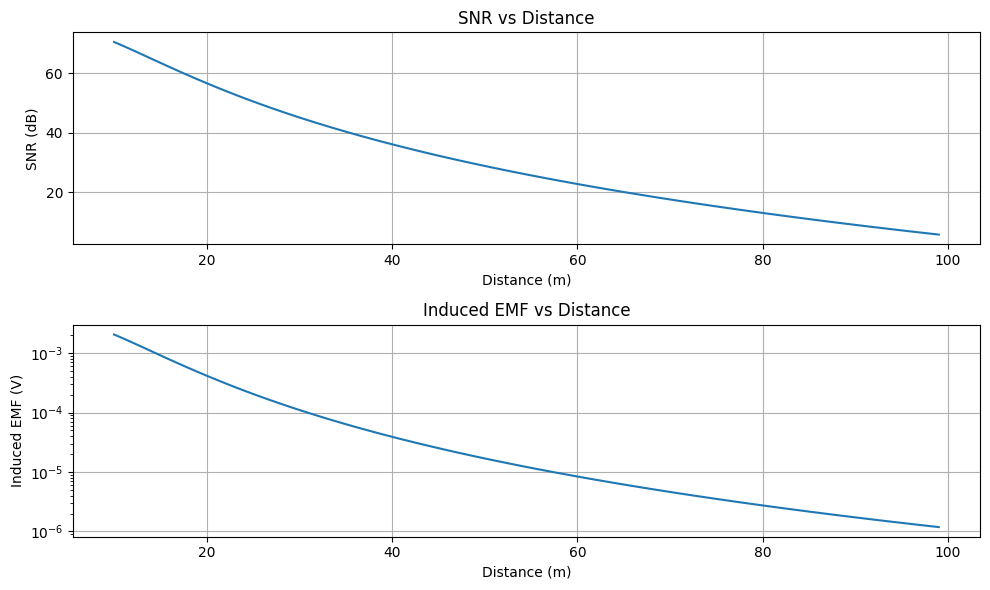

In [20]:
d_range = np.arange(10, 100, 1)

r = np.sqrt(d_range ** 2 + s ** 2)
theta = np.arctan(s / d_range)
m_tx = (r_tx ** 2) * np.pi * i_tx * n_tx
b_r = mu_0 / (2 * np.pi) * (m_tx * np.cos(theta)) / (r ** 3)
b_theta = mu_0 / (4 * np.pi) * (m_tx * np.sin(theta)) / (r ** 3)
b_rx = b_r * np.sin(theta) + b_theta * np.cos(theta)

e_rx = sigma_rx * 2 * np.pi * f * b_rx
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)

plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(d_range, 20 * np.log10(snr_rx_resonance))
plt.title("SNR vs Distance")
plt.xlabel("Distance (m)")
plt.ylabel("SNR (dB)")
plt.grid(True)
plt.subplot(2, 1, 2)
plt.plot(d_range, e_rx)
plt.title("Induced EMF vs Distance")
plt.xlabel("Distance (m)")
plt.ylabel("Induced EMF (V)")
plt.yscale('log')
plt.grid(True)
plt.tight_layout()

### 地下相邻线圈的通信

假定地下两个雷管之间的距离是$d_{adj}$，二者的深度相同，并且两个雷管的轴线是平行的。尝试计算两个雷管之间的通信能力。

In [21]:
d_adj = 10
theta = 90

i_tx_coil = 1
m_tx_coil = (r_tx ** 2) * np.pi * i_tx_coil * n_tx * mu_eff_rx
b_r_coil = mu_0 / (2 * np.pi) * (m_tx_coil * np.cos(np.radians(theta))) / (d_adj ** 3)
b_theta_coil = mu_0 / (4 * np.pi) * (m_tx_coil * np.sin(np.radians(theta))) / (d_adj ** 3)
b_rx_coil = b_theta_coil

e_rx = sigma_rx * 2 * np.pi * f * b_rx_coil
snr_rx_resonance = (a_v_res * e_rx) / np.sqrt((v_noise_thermal * a_v_res) ** 2 + v_noise_amp ** 2)
print(f"接收线圈的感应电动势： {e_rx} V")
print(f"接收线圈的谐振信噪比： {20 * np.log10(snr_rx_resonance)} dB")

接收线圈的感应电动势： 0.05625635988685326 V
接收线圈的谐振信噪比： 99.32367722282459 dB
